In [1]:
import os
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Устройство:", device)
print("Библиотеки успешно загружены!")

PyTorch: 2.12.0+cu130
Устройство: cpu
Библиотеки успешно загружены!


In [2]:
%pip install -q kagglehub


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "alexattia/the-simpsons-characters-dataset"
)

print("Датасет скачан!")
print("Путь:", dataset_path)

print("\nСодержимое папки:")

for item in Path(dataset_path).iterdir():
    print(item.name)

/root/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 1.08G/1.08G [00:07<00:00, 159MB/s]Extracting files...

Датасет скачан!
Путь: /root/.cache/kagglehub/datasets/alexattia/the-simpsons-characters-dataset/versions/4

Содержимое папки:
annotation.txt
characters_illustration.png
kaggle_simpson_testset
number_pic_char.csv
simpsons_dataset
weights.best.hdf5


In [4]:
root = Path(dataset_path)

candidates = [
    p for p in root.rglob("simpsons_dataset")
    if p.is_dir()
]

print("Найденные папки:")

for p in candidates:
    print(p)

if not candidates:
    raise FileNotFoundError(
        "Папка simpsons_dataset не найдена."
    )

DATA_DIR = max(
    candidates,
    key=lambda p: len(list(p.iterdir()))
)

print("\nИспользуем:", DATA_DIR)

classes = sorted([
    p.name for p in DATA_DIR.iterdir()
    if p.is_dir()
])

print("Количество папок персонажей:", len(classes))
print("Примеры классов:", classes[:10])

Найденные папки:
/root/.cache/kagglehub/datasets/alexattia/the-simpsons-characters-dataset/versions/4/simpsons_dataset
/root/.cache/kagglehub/datasets/alexattia/the-simpsons-characters-dataset/versions/4/simpsons_dataset/simpsons_dataset

Используем: /root/.cache/kagglehub/datasets/alexattia/the-simpsons-characters-dataset/versions/4/simpsons_dataset
Количество папок персонажей: 43
Примеры классов: ['abraham_grampa_simpson', 'agnes_skinner', 'apu_nahasapeemapetilon', 'barney_gumble', 'bart_simpson', 'carl_carlson', 'charles_montgomery_burns', 'chief_wiggum', 'cletus_spuckler', 'comic_book_guy']


In [5]:
image_extensions = {".jpg", ".jpeg", ".png"}

class_counts = {}

for class_dir in DATA_DIR.iterdir():

    if not class_dir.is_dir():
        continue

    count = sum(
        1 for p in class_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    )

    class_counts[class_dir.name] = count

df_classes = pd.DataFrame(
    class_counts.items(),
    columns=["Персонаж", "Кол-во изображений"]
)

df_classes = df_classes.sort_values(
    "Кол-во изображений",
    ascending=False
)

print("Всего изображений:", df_classes["Кол-во изображений"].sum())
print("Кол-во классов:", len(df_classes))

display(df_classes.head(15))

Всего изображений: 41866
Кол-во классов: 43


,Персонаж,Кол-во изображений
39,simpsons_dataset,20933
15,homer_simpson,2246
28,ned_flanders,1454
27,moe_szyslak,1452
20,lisa_simpson,1354
4,bart_simpson,1342
22,marge_simpson,1291
17,krusty_the_clown,1206
32,principal_skinner,1194
6,charles_montgomery_burns,1193


In [6]:
from pathlib import Path

root = Path(dataset_path)

print("Структура папок:")

for p in sorted(root.rglob("simpsons_dataset")):
    if p.is_dir():
        print(p)

        children = list(p.iterdir())

        print("Кол-во элементов:", len(children))
        print("Первые элементы:", [x.name for x in children[:10]])
        print("-" * 50)

Структура папок:
/root/.cache/kagglehub/datasets/alexattia/the-simpsons-characters-dataset/versions/4/simpsons_dataset
Кол-во элементов: 43
Первые элементы: ['abraham_grampa_simpson', 'agnes_skinner', 'apu_nahasapeemapetilon', 'barney_gumble', 'bart_simpson', 'carl_carlson', 'charles_montgomery_burns', 'chief_wiggum', 'cletus_spuckler', 'comic_book_guy']
--------------------------------------------------
/root/.cache/kagglehub/datasets/alexattia/the-simpsons-characters-dataset/versions/4/simpsons_dataset/simpsons_dataset
Кол-во элементов: 42
Первые элементы: ['abraham_grampa_simpson', 'agnes_skinner', 'apu_nahasapeemapetilon', 'barney_gumble', 'bart_simpson', 'carl_carlson', 'charles_montgomery_burns', 'chief_wiggum', 'cletus_spuckler', 'comic_book_guy']
--------------------------------------------------


In [7]:
candidate_dirs = [
    p for p in root.rglob("simpsons_dataset")
    if p.is_dir()
]

def valid_character_dirs(folder):
    result = []

    for p in folder.iterdir():
        if not p.is_dir():
            continue

        images = [
            f for f in p.iterdir()
            if f.is_file()
            and f.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ]

        if images:
            result.append(p)

    return result


DATA_DIR = max(
    candidate_dirs,
    key=lambda p: len(valid_character_dirs(p))
)

character_dirs = valid_character_dirs(DATA_DIR)

print("Путь к данным:", DATA_DIR)
print("Кол-во классов:", len(character_dirs))

for p in sorted(character_dirs):
    print(p.name)

Путь к данным: /root/.cache/kagglehub/datasets/alexattia/the-simpsons-characters-dataset/versions/4/simpsons_dataset
Кол-во классов: 42
abraham_grampa_simpson
agnes_skinner
apu_nahasapeemapetilon
barney_gumble
bart_simpson
carl_carlson
charles_montgomery_burns
chief_wiggum
cletus_spuckler
comic_book_guy
disco_stu
edna_krabappel
fat_tony
gil
groundskeeper_willie
homer_simpson
kent_brockman
krusty_the_clown
lenny_leonard
lionel_hutz
lisa_simpson
maggie_simpson
marge_simpson
martin_prince
mayor_quimby
milhouse_van_houten
miss_hoover
moe_szyslak
ned_flanders
nelson_muntz
otto_mann
patty_bouvier
principal_skinner
professor_john_frink
rainier_wolfcastle
ralph_wiggum
selma_bouvier
sideshow_bob
sideshow_mel
snake_jailbird
troy_mcclure
waylon_smithers


In [8]:
class_counts = {}

for p in character_dirs:
    count = sum(
        1 for f in p.iterdir()
        if f.is_file()
        and f.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    class_counts[p.name] = count

df_classes = pd.DataFrame(
    class_counts.items(),
    columns=["Персонаж", "Кол-во изображений"]
).sort_values(
    "Кол-во изображений",
    ascending=False
)

print("Кол-во классов:", len(df_classes))
print("Всего изображений:", df_classes["Кол-во изображений"].sum())

display(df_classes.head(15))

Кол-во классов: 42
Всего изображений: 20933


,Персонаж,Кол-во изображений
15,homer_simpson,2246
28,ned_flanders,1454
27,moe_szyslak,1452
20,lisa_simpson,1354
4,bart_simpson,1342
22,marge_simpson,1291
17,krusty_the_clown,1206
32,principal_skinner,1194
6,charles_montgomery_burns,1193
25,milhouse_van_houten,1079


In [9]:
IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Преобразования изображений готовы!")

Преобразования изображений готовы!


In [10]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset
from PIL import Image

# Список изображений и классов
image_paths = []
labels = []

class_names = sorted(class_counts.keys())
class_to_idx = {
    name: i for i, name in enumerate(class_names)
}

for class_dir in character_dirs:
    for img_path in class_dir.iterdir():

        if (
            img_path.is_file()
            and img_path.suffix.lower() in
            {".jpg", ".jpeg", ".png"}
        ):
            image_paths.append(str(img_path))
            labels.append(class_to_idx[class_dir.name])

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=SEED,
    stratify=labels
)

print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Кол-во классов:", len(class_names))

Train: 16746
Validation: 4187
Кол-во классов: 42


In [11]:
class SimpsonsDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = SimpsonsDataset(
    train_paths,
    train_labels,
    transform=train_transform
)

val_dataset = SimpsonsDataset(
    val_paths,
    val_labels,
    transform=val_transform
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

images, labels_batch = next(iter(train_loader))

print("Размер батча:", images.shape)
print("Размер меток:", labels_batch.shape)
print("Кол-во классов:", len(class_names))

Размер батча: torch.Size([32, 3, 224, 224])
Размер меток: torch.Size([32])
Кол-во классов: 42


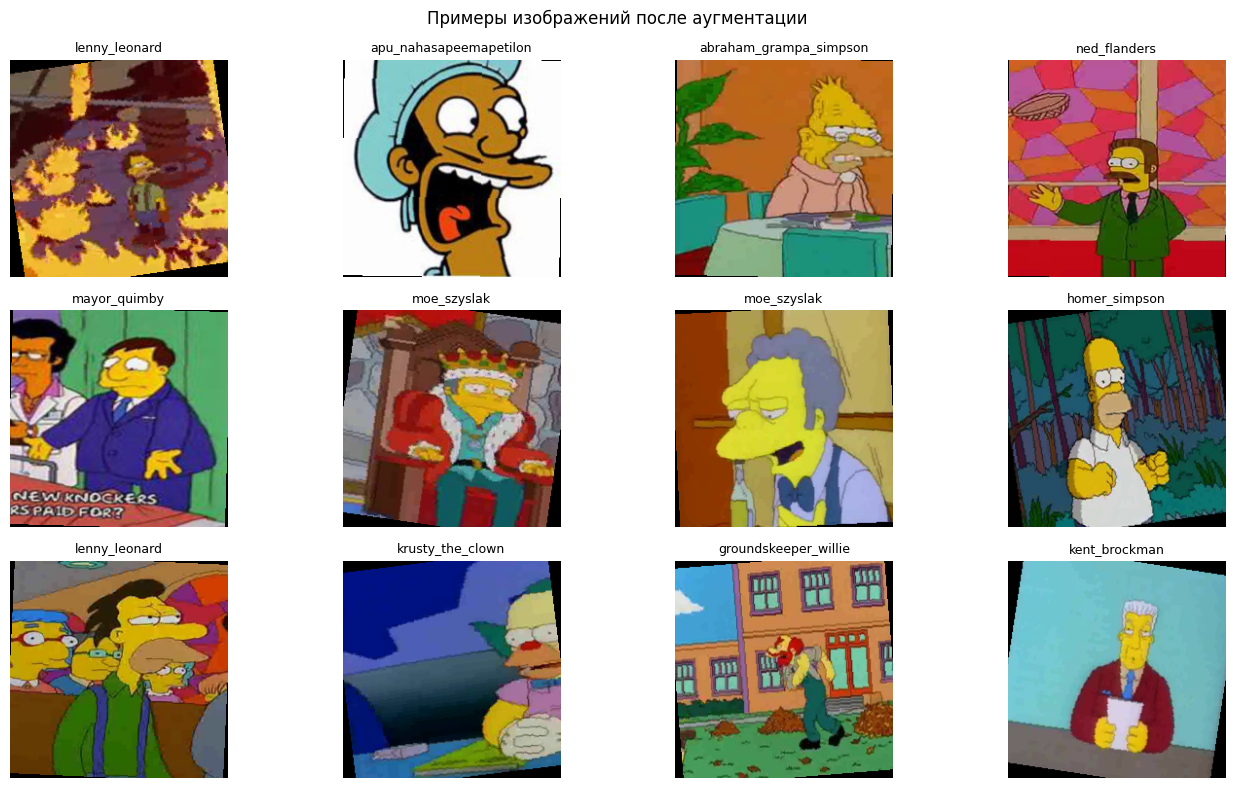

In [12]:
images, labels_batch = next(iter(train_loader))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

plt.figure(figsize=(14, 8))

for i in range(12):
    image = images[i].cpu() * std + mean
    image = image.clamp(0, 1)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.title(class_names[labels_batch[i].item()], fontsize=9)
    plt.axis("off")

plt.suptitle("Примеры изображений после аугментации")
plt.tight_layout()
plt.show()

In [13]:
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)

NUM_CLASSES = len(class_names)

def create_model():
    model = mobilenet_v3_small(
        weights=MobileNet_V3_Small_Weights.DEFAULT
    )

    # Замораживаем все параметры
    for param in model.parameters():
        param.requires_grad = False

    # Заменяем последний полносвязный слой
    in_features = model.classifier[-1].in_features

    model.classifier[-1] = nn.Linear(
        in_features,
        NUM_CLASSES
    )

    return model.to(device)


model = create_model()

print(model.classifier)

print(
    "Всего параметров:",
    sum(p.numel() for p in model.parameters())
)

print(
    "Обучаемых параметров:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth
100%|██████████| 9.83M/9.83M [00:00<00:00, 420MB/s]Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=42, bias=True)
)
Всего параметров: 1560906
Обучаемых параметров: 43050



In [14]:
def train_one_epoch(model, loader, optimizer, criterion,
                    freeze_features=True):

    model.train()

    if freeze_features:
        model.features.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        preds = outputs.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return (
        running_loss / total,
        100 * correct / total
    )


def validate(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * labels.size(0)

            preds = outputs.argmax(dim=1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return (
        running_loss / total,
        100 * correct / total
    )

In [15]:
def run_experiment(
    experiment_name,
    scheduler_type="step",
    epochs=8,
    lr=0.001,
    train_data_loader=None
):

    print("=" * 65)
    print("ЭКСПЕРИМЕНТ:", experiment_name)
    print("=" * 65)

    # Каждый эксперимент начинает обучение с одинаковых
    # предобученных весов и нового классификатора
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    experiment_model = create_model()

    optimizer = optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            experiment_model.parameters()
        ),
        lr=lr,
        weight_decay=0.0001
    )

    criterion = nn.CrossEntropyLoss()

    if scheduler_type == "step":
        scheduler = optim.lr_scheduler.StepLR(
            optimizer,
            step_size=3,
            gamma=0.5
        )

    elif scheduler_type == "cosine":
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs,
            eta_min=0.00001
        )

    else:
        raise ValueError("Неизвестный scheduler_type")

    if train_data_loader is None:
        train_data_loader = train_loader

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "lr": []
    }

    best_accuracy = -1.0
    best_state = None

    for epoch in range(epochs):

        current_lr = optimizer.param_groups[0]["lr"]

        train_loss, train_acc = train_one_epoch(
            experiment_model,
            train_data_loader,
            optimizer,
            criterion,
            freeze_features=True
        )

        val_loss, val_acc = validate(
            experiment_model,
            val_loader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(current_lr)

        if val_acc > best_accuracy:
            best_accuracy = val_acc

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in experiment_model.state_dict().items()
            }

        print(
            f"Эпоха {epoch + 1:02d}/{epochs} | "
            f"LR: {current_lr:.6f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f}"
        )

        scheduler.step()

    experiment_model.load_state_dict(best_state)

    print(
        f"\nЛучшая Validation Accuracy: "
        f"{best_accuracy:.2f}%"
    )

    return experiment_model, history, best_accuracy

In [16]:
step_model, step_history, step_best_acc = run_experiment(
    experiment_name="MobileNetV3 + StepLR",
    scheduler_type="step",
    epochs=8,
    lr=0.001
)

ЭКСПЕРИМЕНТ: MobileNetV3 + StepLR
Эпоха 01/8 | LR: 0.001000 | Train Acc: 55.20% | Val Acc: 68.52% | Val Loss: 1.2210
Эпоха 02/8 | LR: 0.001000 | Train Acc: 69.80% | Val Acc: 74.21% | Val Loss: 1.0052
Эпоха 03/8 | LR: 0.001000 | Train Acc: 73.60% | Val Acc: 75.61% | Val Loss: 0.9231
Эпоха 04/8 | LR: 0.000500 | Train Acc: 75.82% | Val Acc: 77.17% | Val Loss: 0.8844
Эпоха 05/8 | LR: 0.000500 | Train Acc: 76.83% | Val Acc: 77.91% | Val Loss: 0.8485
Эпоха 06/8 | LR: 0.000500 | Train Acc: 77.05% | Val Acc: 78.62% | Val Loss: 0.8310
Эпоха 07/8 | LR: 0.000250 | Train Acc: 78.29% | Val Acc: 78.19% | Val Loss: 0.8268
Эпоха 08/8 | LR: 0.000250 | Train Acc: 78.79% | Val Acc: 79.08% | Val Loss: 0.8139

Лучшая Validation Accuracy: 79.08%


In [17]:
cosine_model, cosine_history, cosine_best_acc = run_experiment(
    experiment_name="MobileNetV3 + CosineAnnealingLR",
    scheduler_type="cosine",
    epochs=8,
    lr=0.001
)

ЭКСПЕРИМЕНТ: MobileNetV3 + CosineAnnealingLR
Эпоха 01/8 | LR: 0.001000 | Train Acc: 55.20% | Val Acc: 68.52% | Val Loss: 1.2210
Эпоха 02/8 | LR: 0.000962 | Train Acc: 69.78% | Val Acc: 73.94% | Val Loss: 1.0089
Эпоха 03/8 | LR: 0.000855 | Train Acc: 73.59% | Val Acc: 75.59% | Val Loss: 0.9310
Эпоха 04/8 | LR: 0.000694 | Train Acc: 75.40% | Val Acc: 77.26% | Val Loss: 0.8906
Эпоха 05/8 | LR: 0.000505 | Train Acc: 76.91% | Val Acc: 77.96% | Val Loss: 0.8480
Эпоха 06/8 | LR: 0.000316 | Train Acc: 77.34% | Val Acc: 78.79% | Val Loss: 0.8327
Эпоха 07/8 | LR: 0.000155 | Train Acc: 78.37% | Val Acc: 78.34% | Val Loss: 0.8317
Эпоха 08/8 | LR: 0.000048 | Train Acc: 78.68% | Val Acc: 78.67% | Val Loss: 0.8246

Лучшая Validation Accuracy: 78.79%


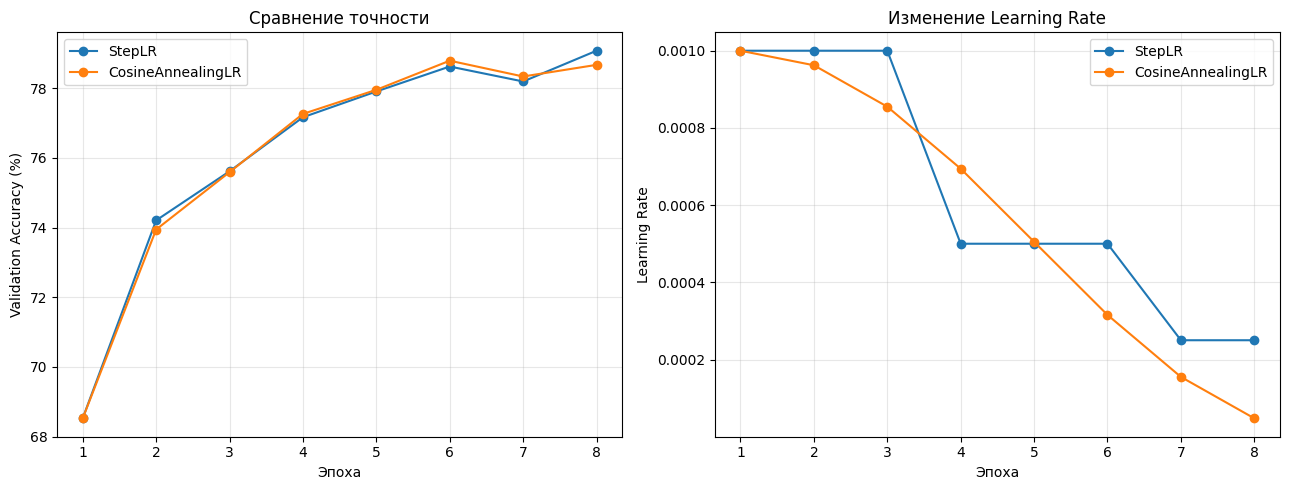

In [18]:
epochs_range = range(1, 9)

plt.figure(figsize=(13, 5))

# Точность на валидации
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    step_history["val_acc"],
    marker="o",
    label="StepLR"
)

plt.plot(
    epochs_range,
    cosine_history["val_acc"],
    marker="o",
    label="CosineAnnealingLR"
)

plt.xlabel("Эпоха")
plt.ylabel("Validation Accuracy (%)")
plt.title("Сравнение точности")
plt.legend()
plt.grid(alpha=0.3)

# Изменение Learning Rate
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    step_history["lr"],
    marker="o",
    label="StepLR"
)

plt.plot(
    epochs_range,
    cosine_history["lr"],
    marker="o",
    label="CosineAnnealingLR"
)

plt.xlabel("Эпоха")
plt.ylabel("Learning Rate")
plt.title("Изменение Learning Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
scheduler_results = pd.DataFrame({
    "Эксперимент": [
        "MobileNetV3 + StepLR",
        "MobileNetV3 + CosineAnnealingLR"
    ],
    "Лучшая Validation Accuracy (%)": [
        step_best_acc,
        cosine_best_acc
    ],
    "Количество эпох": [
        8,
        8
    ]
})

display(scheduler_results)

print(
    "\nРазница между шедулерами:",
    f"{abs(step_best_acc - cosine_best_acc):.2f} п.п."
)

,Эксперимент,Лучшая Validation Accuracy (%),Количество эпох
0,MobileNetV3 + StepLR,79.078099,8
1,MobileNetV3 + CosineAnnealingLR,78.791497,8



Разница между шедулерами: 0.29 п.п.


In [20]:
strong_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.08, 0.35),
        ratio=(0.5, 2.0)
    ),

    transforms.RandomRotation(
        degrees=180
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomPerspective(
        distortion_scale=0.8,
        p=0.9
    ),

    transforms.ColorJitter(
        brightness=0.8,
        contrast=0.8,
        saturation=0.8,
        hue=0.4
    ),

    transforms.RandomGrayscale(
        p=0.5
    ),

    transforms.ToTensor(),

    transforms.RandomErasing(
        p=0.8,
        scale=(0.15, 0.45)
    ),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Сильные аугментации готовы!")

Сильные аугментации готовы!


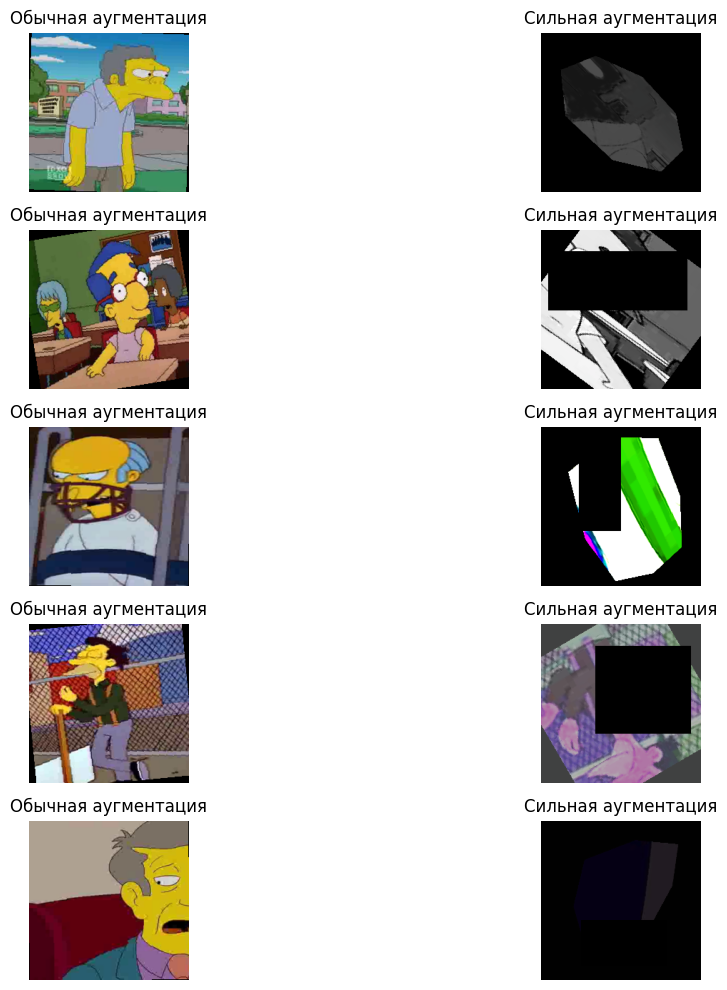

In [21]:
from PIL import Image

plt.figure(figsize=(14, 10))

for i in range(5):

    image = Image.open(train_paths[i]).convert("RGB")

    # Обычные преобразования
    normal_img = train_transform(image)

    # Сильные преобразования
    strong_img = strong_train_transform(image)

    for j, img in enumerate([normal_img, strong_img]):

        img = img.cpu()

        mean = torch.tensor(
            [0.485, 0.456, 0.406]
        ).view(3, 1, 1)

        std = torch.tensor(
            [0.229, 0.224, 0.225]
        ).view(3, 1, 1)

        img = img * std + mean
        img = img.clamp(0, 1)

        plt.subplot(5, 2, i * 2 + j + 1)

        plt.imshow(img.permute(1, 2, 0))

        plt.title(
            "Обычная аугментация"
            if j == 0
            else "Сильная аугментация"
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
strong_train_dataset = SimpsonsDataset(
    train_paths,
    train_labels,
    transform=strong_train_transform
)

strong_train_loader = DataLoader(
    strong_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

print("Train images:", len(strong_train_dataset))
print("Validation images:", len(val_dataset))

images, labels = next(iter(strong_train_loader))

print("Размер батча:", images.shape)

Train images: 16746
Validation images: 4187
Размер батча: torch.Size([32, 3, 224, 224])


In [23]:
strong_model, strong_history, strong_best_acc = run_experiment(
    experiment_name="MobileNetV3 + Strong Augmentations",
    scheduler_type="step",
    epochs=8,
    lr=0.001,
    train_data_loader=strong_train_loader
)

print("\nСРАВНЕНИЕ РЕЗУЛЬТАТОВ")

print(f"Обычные аугментации: {step_best_acc:.2f}%")
print(f"Сильные аугментации: {strong_best_acc:.2f}%")

accuracy_drop = step_best_acc - strong_best_acc

print(f"Снижение Accuracy: {accuracy_drop:.2f} п.п.")

if accuracy_drop > 10:
    print("✅ Условие выполнено: Accuracy снизилась более чем на 10 п.п.")
else:
    print("⚠️ Нужно подобрать другие параметры аугментаций.")

ЭКСПЕРИМЕНТ: MobileNetV3 + Strong Augmentations
Эпоха 01/8 | LR: 0.001000 | Train Acc: 10.59% | Val Acc: 19.13% | Val Loss: 2.9403
Эпоха 02/8 | LR: 0.001000 | Train Acc: 12.09% | Val Acc: 21.59% | Val Loss: 2.8350
Эпоха 03/8 | LR: 0.001000 | Train Acc: 12.06% | Val Acc: 24.39% | Val Loss: 2.7647
Эпоха 04/8 | LR: 0.000500 | Train Acc: 12.52% | Val Acc: 23.12% | Val Loss: 2.7283
Эпоха 05/8 | LR: 0.000500 | Train Acc: 13.14% | Val Acc: 24.53% | Val Loss: 2.6919
Эпоха 06/8 | LR: 0.000500 | Train Acc: 13.03% | Val Acc: 27.49% | Val Loss: 2.6498
Эпоха 07/8 | LR: 0.000250 | Train Acc: 13.20% | Val Acc: 26.61% | Val Loss: 2.6547
Эпоха 08/8 | LR: 0.000250 | Train Acc: 13.48% | Val Acc: 27.11% | Val Loss: 2.6515

Лучшая Validation Accuracy: 27.49%

СРАВНЕНИЕ РЕЗУЛЬТАТОВ
Обычные аугментации: 79.08%
Сильные аугментации: 27.49%
Снижение Accuracy: 51.59 п.п.
✅ Условие выполнено: Accuracy снизилась более чем на 10 п.п.


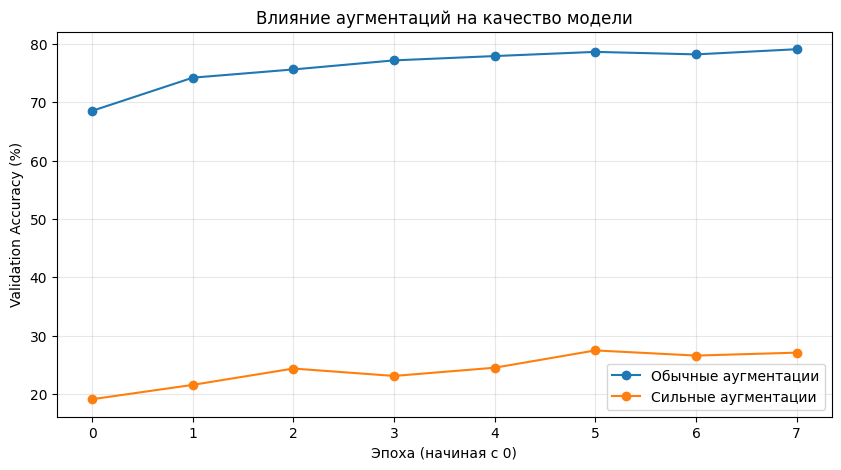

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    step_history["val_acc"],
    marker="o",
    label="Обычные аугментации"
)

plt.plot(
    strong_history["val_acc"],
    marker="o",
    label="Сильные аугментации"
)

plt.xlabel("Эпоха (начиная с 0)")
plt.ylabel("Validation Accuracy (%)")
plt.title("Влияние аугментаций на качество модели")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [25]:
import copy

# Берём лучшую модель из эксперимента StepLR
finetune_model = copy.deepcopy(step_model).to(device)

# Сначала замораживаем все параметры
for param in finetune_model.parameters():
    param.requires_grad = False

# Размораживаем последние 3 блока MobileNetV3
for block in finetune_model.features[-3:]:
    for param in block.parameters():
        param.requires_grad = True

# Размораживаем классификатор
for param in finetune_model.classifier.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in finetune_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in finetune_model.parameters()
    if p.requires_grad
)

print("Всего параметров:", total_params)
print("Обучаемых параметров:", trainable_params)

print(
    "Доля обучаемых параметров:",
    f"{100 * trainable_params / total_params:.2f}%"
)

Всего параметров: 1560906
Обучаемых параметров: 1278538
Доля обучаемых параметров: 81.91%


In [26]:
def fine_tune_model(model, epochs=8):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        [
            {
                "params": [
                    p for p in model.features.parameters()
                    if p.requires_grad
                ],
                "lr": 0.00005
            },
            {
                "params": [
                    p for p in model.classifier.parameters()
                    if p.requires_grad
                ],
                "lr": 0.0002
            }
        ],
        weight_decay=0.0001
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs,
        eta_min=0.000001
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "lr": []
    }

    best_acc = -1.0
    best_state = None

    for epoch in range(epochs):

        model.train()

        # Замороженные блоки не обновляют
        # статистики BatchNorm
        for block in model.features[:-3]:
            block.eval()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)

            preds = outputs.argmax(dim=1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = 100 * correct / total

        val_loss, val_acc = validate(
            model,
            val_loader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(
            optimizer.param_groups[0]["lr"]
        )

        if val_acc > best_acc:

            best_acc = val_acc

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Эпоха {epoch + 1:02d}/{epochs} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f}"
        )

        scheduler.step()

    # Возвращаем лучшие веса
    model.load_state_dict(best_state)

    print("\nЛучшая Validation Accuracy:", f"{best_acc:.2f}%")

    return model, history, best_acc

In [27]:
finetune_model, finetune_history, finetune_best_acc = fine_tune_model(
    finetune_model,
    epochs=8
)

print("\nРЕЗУЛЬТАТ FINE-TUNING")
print("-" * 45)

print(f"До Fine-tuning: {step_best_acc:.2f}%")
print(f"После Fine-tuning: {finetune_best_acc:.2f}%")

difference = finetune_best_acc - step_best_acc

print(f"Изменение Accuracy: {difference:+.2f} п.п.")

Эпоха 01/8 | Train Acc: 80.83% | Val Acc: 87.06% | Val Loss: 0.4830
Эпоха 02/8 | Train Acc: 87.51% | Val Acc: 89.01% | Val Loss: 0.4094
Эпоха 03/8 | Train Acc: 90.48% | Val Acc: 90.52% | Val Loss: 0.3524
Эпоха 04/8 | Train Acc: 92.31% | Val Acc: 91.62% | Val Loss: 0.3313
Эпоха 05/8 | Train Acc: 93.59% | Val Acc: 92.14% | Val Loss: 0.3107
Эпоха 06/8 | Train Acc: 94.30% | Val Acc: 92.02% | Val Loss: 0.3096
Эпоха 07/8 | Train Acc: 94.77% | Val Acc: 92.43% | Val Loss: 0.2993
Эпоха 08/8 | Train Acc: 94.92% | Val Acc: 92.48% | Val Loss: 0.2979

Лучшая Validation Accuracy: 92.48%

РЕЗУЛЬТАТ FINE-TUNING
---------------------------------------------
До Fine-tuning: 79.08%
После Fine-tuning: 92.48%
Изменение Accuracy: +13.40 п.п.


In [28]:
results_df = pd.DataFrame({
    "Эксперимент": [
        "StepLR",
        "CosineAnnealingLR",
        "Сильные аугментации",
        "Fine-tuning"
    ],
    "Validation Accuracy (%)": [
        step_best_acc,
        cosine_best_acc,
        strong_best_acc,
        finetune_best_acc
    ]
})

results_df = results_df.sort_values(
    "Validation Accuracy (%)",
    ascending=False
)

display(results_df)

best_experiment = results_df.iloc[0]

print("\nЛучший эксперимент:", best_experiment["Эксперимент"])
print(
    "Лучшая Accuracy:",
    f"{best_experiment['Validation Accuracy (%)']:.2f}%"
)

,Эксперимент,Validation Accuracy (%)
3,Fine-tuning,92.476714
0,StepLR,79.078099
1,CosineAnnealingLR,78.791497
2,Сильные аугментации,27.489850



Лучший эксперимент: Fine-tuning
Лучшая Accuracy: 92.48%


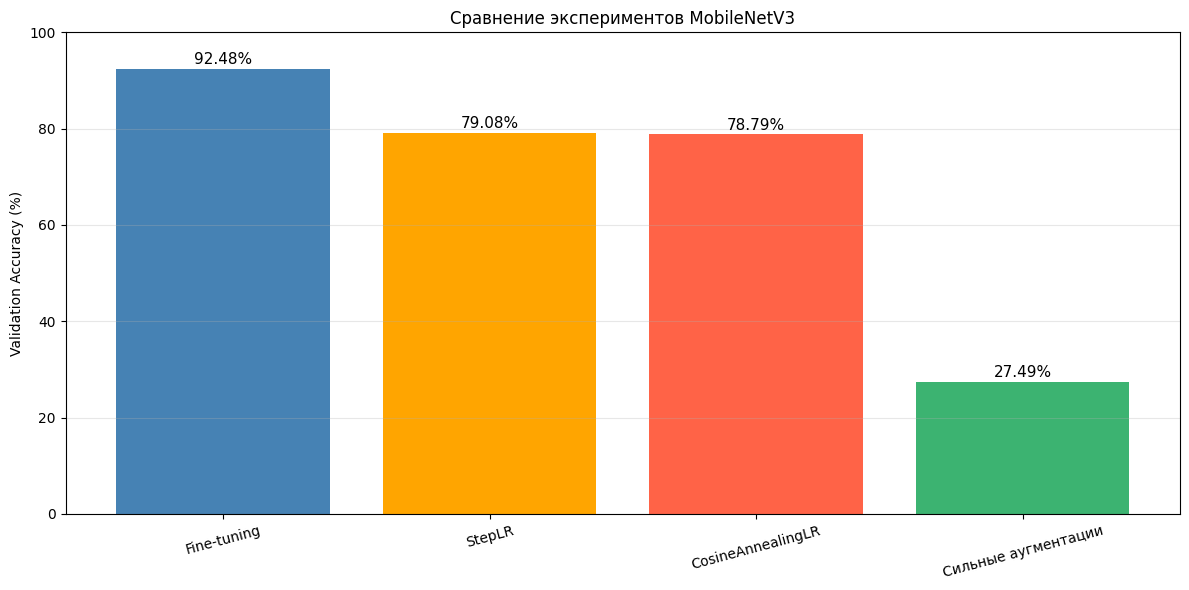

In [29]:
plt.figure(figsize=(12, 6))

colors = [
    "steelblue",
    "orange",
    "tomato",
    "mediumseagreen"
]

bars = plt.bar(
    results_df["Эксперимент"],
    results_df["Validation Accuracy (%)"],
    color=colors
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center",
        fontsize=11
    )

plt.ylabel("Validation Accuracy (%)")
plt.title("Сравнение экспериментов MobileNetV3")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

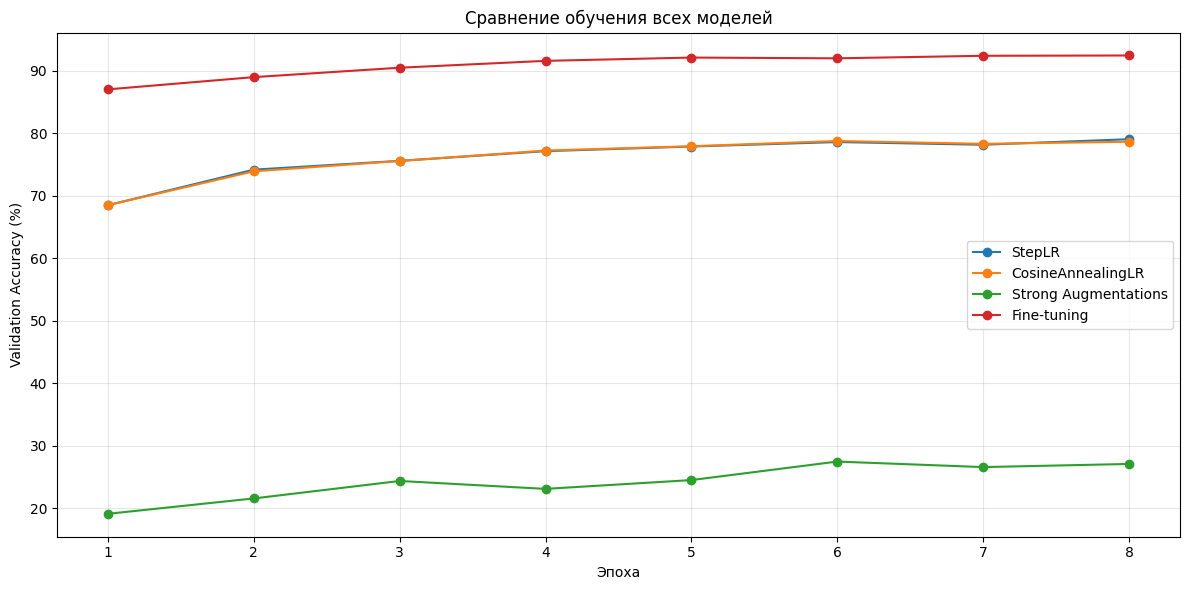

In [30]:
plt.figure(figsize=(12, 6))

experiments = {
    "StepLR": step_history,
    "CosineAnnealingLR": cosine_history,
    "Strong Augmentations": strong_history,
    "Fine-tuning": finetune_history
}

for name, history in experiments.items():

    epochs_range = range(
        1,
        len(history["val_acc"]) + 1
    )

    plt.plot(
        epochs_range,
        history["val_acc"],
        marker="o",
        label=name
    )

plt.xlabel("Эпоха")
plt.ylabel("Validation Accuracy (%)")
plt.title("Сравнение обучения всех моделей")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Лучшая модель: Fine-tuning


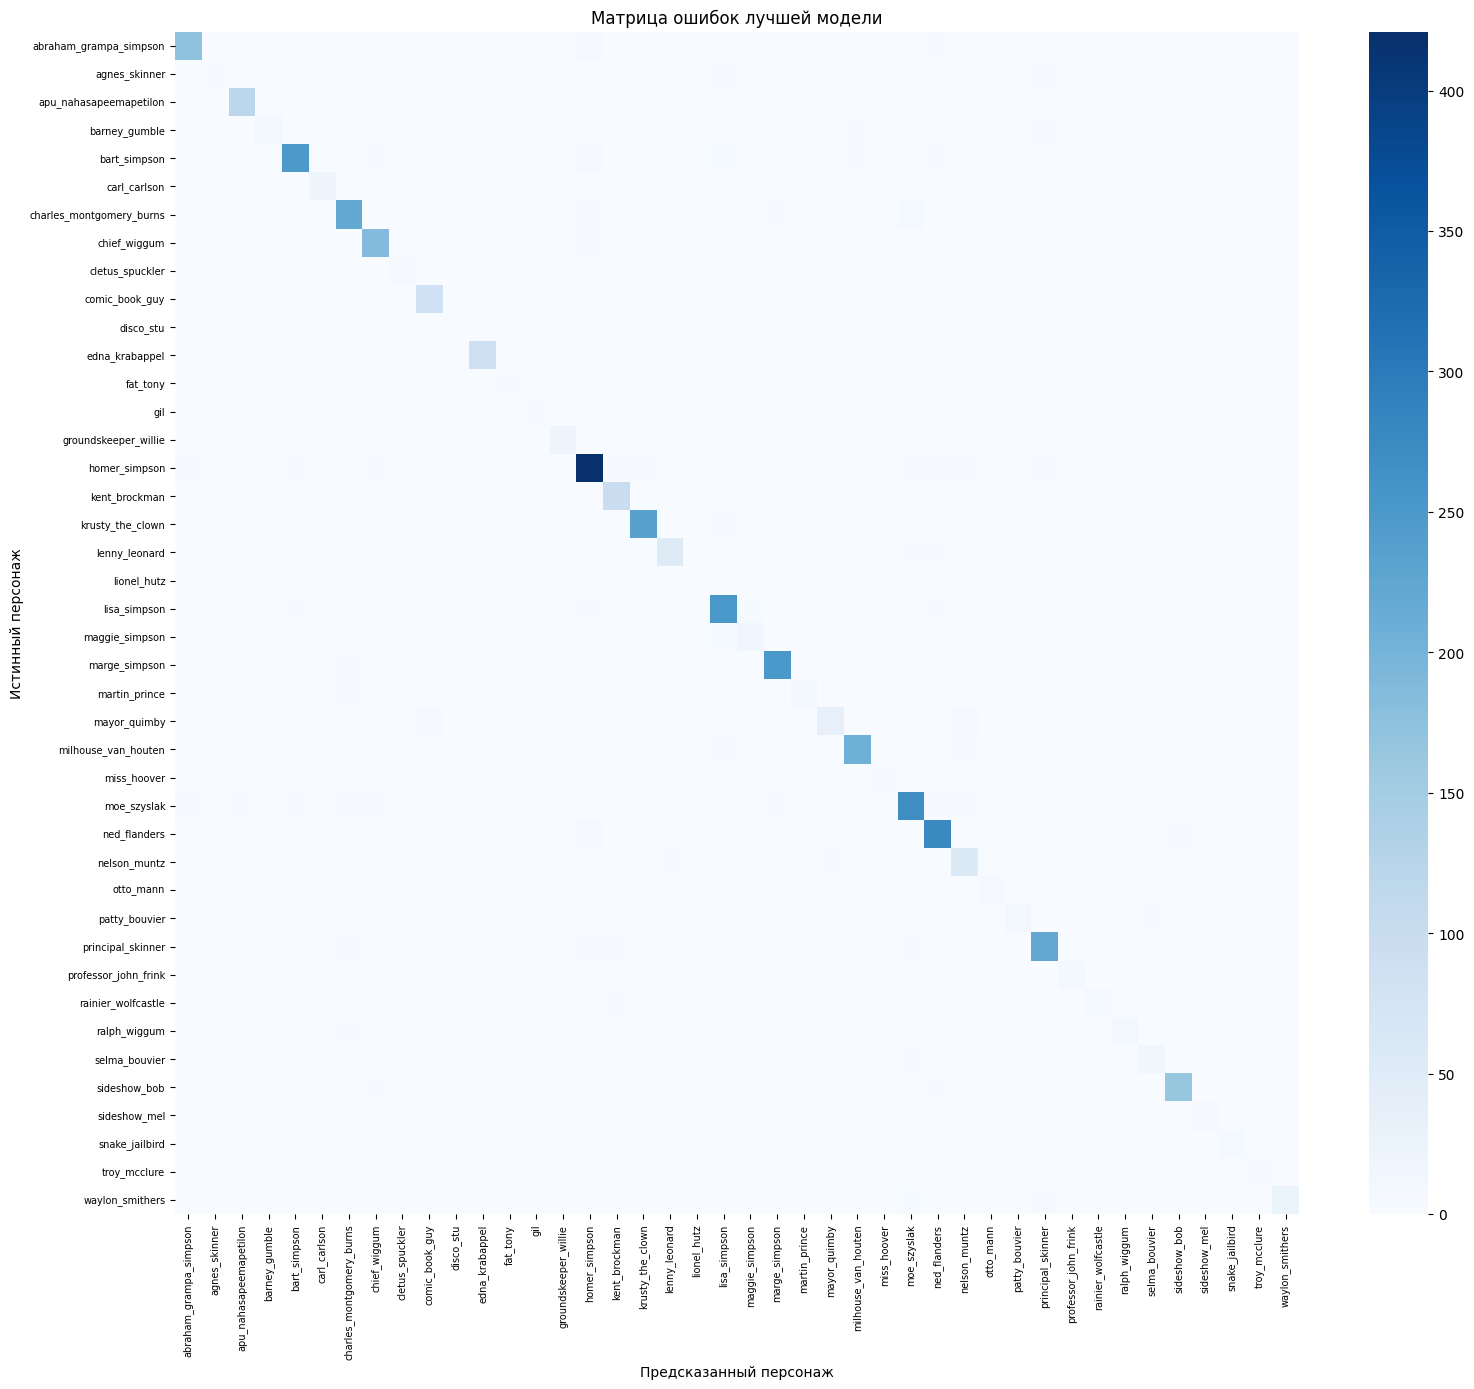

In [31]:
model_candidates = {
    "StepLR": (step_model, step_best_acc),
    "CosineAnnealingLR": (cosine_model, cosine_best_acc),
    "Fine-tuning": (finetune_model, finetune_best_acc)
}

best_model_name = max(
    model_candidates,
    key=lambda name: model_candidates[name][1]
)

best_model = model_candidates[best_model_name][0]

print("Лучшая модель:", best_model_name)

best_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Матрица ошибок лучшей модели")
plt.xlabel("Предсказанный персонаж")
plt.ylabel("Истинный персонаж")

plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)

plt.tight_layout()
plt.show()

In [32]:
print("ОТЧЁТ ПО КАЧЕСТВУ КЛАССИФИКАЦИИ")
print("=" * 60)

print(
    classification_report(
        all_labels,
        all_preds,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

ОТЧЁТ ПО КАЧЕСТВУ КЛАССИФИКАЦИИ
                          precision    recall  f1-score   support

  abraham_grampa_simpson      0.946     0.951     0.948       183
           agnes_skinner      1.000     0.375     0.545         8
  apu_nahasapeemapetilon      0.968     0.960     0.964       125
           barney_gumble      0.929     0.619     0.743        21
            bart_simpson      0.936     0.929     0.933       268
            carl_carlson      1.000     0.950     0.974        20
charles_montgomery_burns      0.902     0.921     0.911       239
            chief_wiggum      0.944     0.949     0.947       197
         cletus_spuckler      0.857     0.667     0.750         9
          comic_book_guy      0.879     0.926     0.902        94
               disco_stu      1.000     0.500     0.667         2
          edna_krabappel      0.957     0.967     0.962        91
                fat_tony      0.750     0.600     0.667         5
                     gil      0.667     0.4

In [33]:
torch.save(
    {
        "model_state_dict": best_model.state_dict(),
        "model_name": best_model_name,
        "num_classes": len(class_names),
        "class_names": class_names
    },
    "simpsons_best_model.pth"
)

print("Лучшая модель сохранена!")

Лучшая модель сохранена!


In [34]:
import json

results = {
    "StepLR": float(step_best_acc),
    "CosineAnnealingLR": float(cosine_best_acc),
    "Strong_Augmentations": float(strong_best_acc),
    "Fine_Tuning": float(finetune_best_acc)
}

with open("simpsons_experiment_results.json", "w") as f:
    json.dump(
        results,
        f,
        indent=4,
        ensure_ascii=False
    )

results_df.to_csv(
    "simpsons_experiments.csv",
    index=False
)

print("Результаты сохранены!")

Результаты сохранены!


In [35]:
scheduler_difference = step_best_acc - cosine_best_acc
augmentation_drop = step_best_acc - strong_best_acc
finetune_gain = finetune_best_acc - step_best_acc

print("=" * 65)
print("ИТОГОВЫЙ АНАЛИЗ ЭКСПЕРИМЕНТОВ")
print("=" * 65)

print("\n1. СРАВНЕНИЕ LR SCHEDULERS")

print(f"StepLR: {step_best_acc:.2f}%")
print(f"CosineAnnealingLR: {cosine_best_acc:.2f}%")

if scheduler_difference > 0:
    print(
        f"StepLR лучше на {scheduler_difference:.2f} п.п."
    )
elif scheduler_difference < 0:
    print(
        f"CosineAnnealingLR лучше на "
        f"{abs(scheduler_difference):.2f} п.п."
    )
else:
    print("Оба планировщика показали одинаковую точность.")

print("\n2. ВЛИЯНИЕ АУГМЕНТАЦИЙ")

print(f"Обычные аугментации: {step_best_acc:.2f}%")
print(f"Сильные аугментации: {strong_best_acc:.2f}%")
print(f"Снижение: {augmentation_drop:.2f} п.п.")

if augmentation_drop > 10:
    print("Условие ухудшения более чем на 10 п.п. выполнено.")

print("\n3. FINE-TUNING")

print(f"До дообучения: {step_best_acc:.2f}%")
print(f"После дообучения: {finetune_best_acc:.2f}%")

if finetune_gain > 0:
    print(
        f"Fine-tuning улучшил качество на "
        f"{finetune_gain:.2f} п.п."
    )
elif finetune_gain < 0:
    print(
        f"Fine-tuning ухудшил качество на "
        f"{abs(finetune_gain):.2f} п.п."
    )
else:
    print("Fine-tuning не изменил лучшую точность.")

print("\nЛУЧШАЯ МОДЕЛЬ:", best_model_name)

ИТОГОВЫЙ АНАЛИЗ ЭКСПЕРИМЕНТОВ

1. СРАВНЕНИЕ LR SCHEDULERS
StepLR: 79.08%
CosineAnnealingLR: 78.79%
StepLR лучше на 0.29 п.п.

2. ВЛИЯНИЕ АУГМЕНТАЦИЙ
Обычные аугментации: 79.08%
Сильные аугментации: 27.49%
Снижение: 51.59 п.п.
Условие ухудшения более чем на 10 п.п. выполнено.

3. FINE-TUNING
До дообучения: 79.08%
После дообучения: 92.48%
Fine-tuning улучшил качество на 13.40 п.п.

ЛУЧШАЯ МОДЕЛЬ: Fine-tuning


Для экспериментов использовался датасет The Simpsons Characters Dataset, содержащий 20 933 изображения 42 персонажей\.

Данные разделены на обучающую и валидационную выборки в соотношении 80/20 со стратификацией по классам\.

Для классификации выбрана архитектура MobileNetV3 Small с предобученными весами ImageNet\.

Первоначально параметры сети извлечения признаков были заморожены, а последний классифицирующий слой заменен новым слоем для 42 классов\.

Были проведены два эксперимента с различными планировщиками скорости обучения\.

- StepLR \- лучшая Accuracy \- 79,08%

- CosineAnnealingLR \- лучшая Accuracy \- 78,79%

StepLR уменьшал Learning Rate ступенчато, тогда как CosineAnnealingLR обеспечивал плавное снижение скорости обучения\.

Разница составила 0,29 п\.п\. в пользу StepLR\.

Вывод: оба планировщика успешно применены и обеспечили сопоставимое качество\. В условиях проведенных экспериментов StepLR оказался немного эффективнее, однако разница несущественная\.

 Для исследования влияния сильных аугментаций использовались геометрические и цветовые преобразования: RandomResizedCrop, RandomRotation, RandomPerspective, ColorJitter, RandomGrayscale и RandomErasing\.

- обычные \- лучшая Accuracy \- 79,08%

- сильные \- лучшая Accuracy \- 27,49%

Основная причина ухудшения \- потеря значимых визуальных признаков\. Сильное обрезание может удалять части лица и тела персонажей, повороты и перспективные искажения изменяют их привычную форму, а цветовые преобразования нарушают характерную цветовую палитру\.

Таким образом, чрезмерная аугментация не всегда улучшает обобщающую способность модели\. При слишком сильных преобразованиях обучающие изображения становятся менее информативными для исходной задачи классификации\.

Требование по снижению Accuracy более чем на 10 процентных пунктов выполнено\.

На следующем этапе проведено дообучение MobileNetV3 Small\.

Были разморожены последние три блока извлечения признаков и классификатор\. Для обучения использовались разные значения Learning Rate: меньшие для предобученных блоков и большие для классификатора\.

- До Fine\-tuning \- лучшая Accuracy \- 79,08%,

- После Fine\-tuning \- лучшая Accuracy \- 92,48%

Результат показывает, что адаптация последних слоев предобученной модели к особенностям нового датасета позволила сильно повысить качество классификации\.

При первоначальном Transfer Learning обучался преимущественно новый классификатор, использующий уже сформированные признаки ImageNet\.

После разморозки части сети модель получила возможность изменять и сами высокоуровневые признаки, что оказалось полезным для распознавания персонажей\.

Общий вывод

В ходе практической работы были успешно реализованы и исследованы различные методы Transfer Learning\.

Проведенные эксперименты показали, что:

1\. LR Schedulers позволяют управлять скоростью обучения, при этом их влияние на качество зависит от настроек и условий эксперимента\.
2\. Чрезмерно сильные аугментации могут существенно ухудшать качество классификации из\-за потери важных признаков изображений\.
3\. Использование предобученной MobileNetV3 позволяет решать новую задачу классификации без обучения всей сети с нуля\.
4\. Fine\-tuning последних блоков значительно повысил качество модели — с 79,08% до 92,48%\.

Полученные результаты демонстрируют эффективность Fine\-tuning и важность правильного выбора аугментаций и параметров обучения\.

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=06975d2a-20b8-4e37-9f29-cb3d1f85629c' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>